In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
from utils_experiments import *
import os
from tqdm import tqdm

In [2]:
rebecca_data_ir = pd.read_csv('processed_data_new/rebecca_data_ir_final.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-4])) + list(rebecca_data_ir.columns[-4:])

rebecca_data_raman = pd.read_csv('processed_data_new/rebecca_data_raman_final_specy.csv')
del rebecca_data_raman['Unnamed: 0']
rebecca_data_raman.columns = list(np.float64(rebecca_data_raman.columns[:-4])) + list(rebecca_data_raman.columns[-4:])

In [150]:
poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

IR_spectra_mix_std = pd.read_csv('processed_data_new/data_ir_mix_std_rebecca.csv')
del IR_spectra_mix_std['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix_std.columns = list(np.float64(IR_spectra_mix_std.columns[:-8])) + list(IR_spectra_mix_std.columns[-8:])

IR_spectra_mix_std = (IR_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix_std.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_std_rest = IR_spectra_mix_std.loc[[x not in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std.loc[IR_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix_std = IR_spectra_mix_std.sort_values('id').reset_index(drop=True)


#Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca.csv')
Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca_specy.csv')
#notes_mix_std_rest = np.array(Raman_spectra_mix_std['comments'])
notes_mix_std = Raman_spectra_mix_std.iloc[:,-5:]

notes_mix_std = (notes_mix_std.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix_std.loc[notes_mix_std['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_std_rest[[x is np.nan for x in notes_mix_std_rest]] = ''
del Raman_spectra_mix_std['Unnamed: 0']
Raman_spectra_mix_std.columns = list(np.float64(Raman_spectra_mix_std.columns[:-7])) + list(Raman_spectra_mix_std.columns[-7:])
Raman_spectra_mix_std = (Raman_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix_std.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.sort_values('id').reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_std_rest = Raman_spectra_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
notes_mix_std_rest = notes_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

Raman_spectra_mix_std.loc[Raman_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'

#ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) for x, y, z in zip(notes_mix_std['polymer_raman'], notes_mix_std['polymer_ir'], notes_mix_std['polymer_overall'])]
#Raman_spectra_mix_std = Raman_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)


In [151]:
poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

IR_spectra_mix = pd.read_csv('processed_data_new/data_ir_mix_rebecca.csv')
del IR_spectra_mix['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix.columns = list(np.float64(IR_spectra_mix.columns[:-8])) + list(IR_spectra_mix.columns[-8:])

IR_spectra_mix = (IR_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_rest = IR_spectra_mix.loc[[x not in poly_list for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
#IR_spectra_mix = IR_spectra_mix.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix = IR_spectra_mix.loc[[x in poly_list for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix.loc[IR_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix = IR_spectra_mix.sort_values('id').reset_index(drop=True)


#Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca.csv')
Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca_specy.csv')
#notes_mix_rest = np.array(Raman_spectra_mix['comments'])
notes_mix = Raman_spectra_mix.iloc[:,-5:]

notes_mix = (notes_mix.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix.loc[notes_mix['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix.loc[notes_mix['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix.loc[notes_mix['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_rest[[x is np.nan for x in notes_mix_rest]] = ''
del Raman_spectra_mix['Unnamed: 0']
Raman_spectra_mix.columns = list(np.float64(Raman_spectra_mix.columns[:-7])) + list(Raman_spectra_mix.columns[-7:])
Raman_spectra_mix = (Raman_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.sort_values('id').reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_rest = Raman_spectra_mix.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
notes_mix_rest = notes_mix.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

Raman_spectra_mix.loc[Raman_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'

#ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) for x, y, z in zip(notes_mix['polymer_raman'], notes_mix['polymer_ir'], notes_mix['polymer_overall'])]
#Raman_spectra_mix = Raman_spectra_mix.loc[ids_ideal_set,:].reset_index(drop=True)
#IR_spectra_mix = IR_spectra_mix.loc[ids_ideal_set,:].reset_index(drop=True)


In [5]:
Raman_spectra_mix.groupby('polymer').count().iloc[:,-1:]

,id
polymer,
PE,125
PP,96
PSL,86


In [6]:
Raman_spectra_mix_std.groupby('polymer').count().iloc[:,-1:]

,id
polymer,
NH2SO4,45
NaNO3,13
PE,38
PP,4
PSL,13
sucrose,111


In [266]:
IR_spectra_amb = pd.read_csv('processed_data_new/data_ir_amb_rebecca.csv')
del IR_spectra_amb['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_amb.columns = list(np.float64(IR_spectra_amb.columns[:-8])) + list(IR_spectra_amb.columns[-8:])
IR_spectra_amb_rest = IR_spectra_amb.loc[[x not in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_amb['polymer']],:].reset_index(drop=True)
#IR_spectra_amb = IR_spectra_amb.loc[[x in ['LDPE', 'PP', 'PSL', 'AMB'] for x in IR_spectra_amb['polymer']],:].reset_index(drop=True)
IR_spectra_amb = IR_spectra_amb.loc[[x in ['AMB','LDPE', 'PP', 'PSL'] for x in IR_spectra_amb['polymer']],:].reset_index(drop=True)
IR_spectra_amb.loc[IR_spectra_amb['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_amb.loc[IR_spectra_amb['polymer'] == 'AMB','polymer'] = 'z_AMB'

Raman_spectra_amb = pd.read_csv('processed_data_new/data_raman_amb_rebecca_specy.csv')
del Raman_spectra_amb['Unnamed: 0']
Raman_spectra_amb.columns = list(np.float64(Raman_spectra_amb.columns[:-7])) + list(Raman_spectra_amb.columns[-7:])
Raman_spectra_amb_rest = Raman_spectra_amb.loc[[x not in ['LDPE', 'PP', 'PSL'] for x in Raman_spectra_amb['polymer']],:].reset_index(drop=True)
#Raman_spectra_amb = Raman_spectra_amb.loc[[x in ['LDPE', 'PP', 'PSL', 'AMB'] for x in Raman_spectra_amb['polymer']],:].reset_index(drop=True)
Raman_spectra_amb = Raman_spectra_amb.loc[[x in ['AMB','LDPE', 'PP', 'PSL'] for x in Raman_spectra_amb['polymer']],:].reset_index(drop=True)
Raman_spectra_amb.loc[Raman_spectra_amb['polymer'] == 'LDPE','polymer'] = 'PE'
Raman_spectra_amb.loc[Raman_spectra_amb['polymer'] == 'AMB','polymer'] = 'z_AMB'

poly_list_amb = poly_list+['z_AMB']+['AMB']
ids_ideal_set = [(x in poly_list_amb) and (y in poly_list_amb) and (z in poly_list_amb) for x, y, z in zip(Raman_spectra_amb['polymer_raman'], Raman_spectra_amb['polymer_ir'], Raman_spectra_amb['polymer'])]

IR_spectra_amb = IR_spectra_amb.iloc[:,list(range(IR_spectra_amb.shape[1]-8))+[-8,-7,-5,-4,-3,-6,-2,-1]]
Raman_spectra_amb = Raman_spectra_amb.iloc[:,list(range(Raman_spectra_amb.shape[1]-4))+[-1]]
idx_nan_raman = np.isnan(Raman_spectra_amb.iloc[:,:-4]).sum(1)>0

#Raman_spectra_amb = Raman_spectra_amb.loc[ids_ideal_set,:].reset_index(drop=True)
#IR_spectra_amb = IR_spectra_amb.loc[ids_ideal_set,:].reset_index(drop=True)
Raman_spectra_amb = Raman_spectra_amb.loc[~idx_nan_raman,:].reset_index(drop=True)
IR_spectra_amb = IR_spectra_amb.loc[~idx_nan_raman,:].reset_index(drop=True)


In [267]:
IR_spectra_amb.groupby('polymer').count().iloc[:,-1:]

,background
polymer,
PE,32
PP,6
PSL,33
z_AMB,51


In [268]:
np.where(IR_spectra_amb.iloc[:,:-8].std(1)<0.0001)#.query('polymer == "z_AMB"')

(array([], dtype=int64),)

In [269]:
np.where(Raman_spectra_amb.iloc[:,:-4].std(1)<0.0001)

(array([], dtype=int64),)

In [270]:
np.unique(np.where(np.isnan(Raman_spectra_amb.iloc[:,:-4]))[0])

array([], dtype=int64)

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
0,-0.202868,-0.202868,-0.202868,-0.202868,-0.202868,-0.202868,-0.202868,-0.202868,-0.202868,-0.202868,...,-0.233505,-0.233505,-0.233505,-0.233505,-0.233505,-0.233505,0,0,PSL,1
1,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,...,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,-0.428132,0,0,z_AMB,2
2,-0.199495,-0.199495,-0.199495,-0.199495,-0.199495,-0.199495,-0.199495,-0.199495,-0.199495,-0.199495,...,-0.240345,-0.240345,-0.240345,-0.240345,-0.240345,-0.240345,0,0,PE,5
3,-0.260510,-0.260510,-0.260510,-0.260510,-0.260510,-0.260510,-0.260510,-0.260510,-0.260510,-0.260510,...,-0.335109,-0.335109,-0.335109,-0.335109,-0.335109,-0.335109,0,0,z_AMB,6
4,-0.458999,-0.458999,-0.458999,-0.458999,-0.458999,-0.458999,-0.458999,-0.458999,-0.458999,-0.458999,...,-0.458999,-0.458999,-0.458999,-0.458999,-0.458999,-0.458999,0,0,z_AMB,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122,-0.183869,-0.183869,-0.183869,-0.183869,-0.183869,-0.183869,-0.183869,-0.183869,-0.183869,-0.183869,...,-0.183869,-0.183869,-0.183869,-0.183869,-0.183869,-0.183869,0,0,PSL,250
123,-0.268105,-0.268105,-0.268105,-0.268105,-0.268105,-0.268105,-0.268105,-0.268105,-0.268105,-0.268105,...,-0.268105,-0.268105,-0.268105,-0.268105,-0.268105,-0.268105,0,0,z_AMB,251
124,-0.052962,-0.052962,-0.052962,-0.052962,-0.052962,-0.052962,-0.052962,-0.052962,-0.052962,-0.052962,...,-0.565249,-0.565249,-0.565249,-0.565249,-0.565249,-0.565249,0,0,PSL,253
125,-0.153548,-0.153548,-0.153548,-0.153548,-0.153548,-0.153548,-0.153548,-0.153548,-0.153548,-0.153548,...,-0.153548,-0.153548,-0.153548,-0.153548,-0.153548,-0.153548,0,0,z_AMB,254


In [226]:
def process_data(rebecca_data_ir, rebecca_data_raman, IR_spectra, Raman_spectra, range_r=[550, 3500]):
    
    #range_r = [550, 3500] 
    
    wn_rb = np.array(rebecca_data_ir.columns[:-4])
    idx_rb = list(np.logical_or(np.logical_and(wn_rb > 980, wn_rb < 1800),
                           np.logical_and(wn_rb > 2720, wn_rb < 2950)
                          ) ) + [False]*4
    
    wn_rb_r = np.array(rebecca_data_raman.columns[:-4])
    idx_rb_r = list(np.logical_and(wn_rb_r > range_r[0], wn_rb_r < range_r[1])) + [False]*4


    wn_rb_amb = np.array(IR_spectra.columns[:-8])
    idx_rb_amb = list(np.logical_or(np.logical_and(wn_rb_amb > 980, wn_rb_amb < 1800),
                           np.logical_and(wn_rb_amb > 2720, wn_rb_amb < 2950) #2993.64990234375-10
                          ) ) + [False]*8
    
    wn_rb_amb_r = np.array(Raman_spectra.columns[:-4])
    idx_rb_amb_r = list(np.logical_and(wn_rb_amb_r > range_r[0], wn_rb_amb_r < range_r[1])) + [False]*4
    
    x_train_ir = rebecca_data_ir.iloc[:,idx_rb].to_numpy()
    x_train_ir = (x_train_ir - x_train_ir.mean(1)[:, None]) / x_train_ir.std(1)[:, None]
    
    y_train_ir = rebecca_data_ir.iloc[:,-2]

    x_train_raman = rebecca_data_raman.iloc[:,idx_rb_r].to_numpy()
    x_train_raman = (x_train_raman - x_train_raman.mean(1)[:, None]) / x_train_raman.std(1)[:, None]
    
    y_train_raman = rebecca_data_raman.iloc[:,-2]

    x_ir = IR_spectra.iloc[:,idx_rb_amb].to_numpy()
    x_ir = (x_ir - x_ir.mean(1)[:, None]) / x_ir.std(1)[:, None]    

    x_raman = Raman_spectra.iloc[:,idx_rb_amb_r].to_numpy()
    x_raman = (x_raman - x_raman.mean(1)[:, None]) / x_raman.std(1)[:, None]
    y_test = IR_spectra.iloc[:,-3]
    
    idx_test = np.sum(np.isnan(x_raman), axis=1) == 0
    ids_test = IR_spectra.loc[idx_test,'id']
    
    x_ir = x_ir[idx_test,:]
    x_raman = x_raman[idx_test,:]
    
    y_raman = y_test[idx_test]
    y_ir = y_test[idx_test]
    
    #y_test[y_test == 'LDPE'] = 'PE'
    
    poly_list = list(np.unique(np.concatenate([y_train_ir, y_train_raman, y_ir]))) 
    label_table = pd.DataFrame({'label':np.arange(len(poly_list)), 'polymer':poly_list})
    
    label_train_Raman = np.array(pd.DataFrame(y_train_raman).merge(label_table, left_on="polymer", right_on="polymer")['label'])
    label_train_IR = np.array(pd.DataFrame(y_train_ir).merge(label_table, left_on="polymer", right_on="polymer")['label'])
    
    label_ir = np.array(pd.DataFrame(y_ir).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])
    
    label_raman = np.array(pd.DataFrame(y_raman).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])
    
    return x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table, ids_test


In [152]:
Raman_spectra_amb.groupby('polymer').count()['id']

polymer
PE       32
PP        6
PSL      34
z_AMB    55
Name: id, dtype: int64

In [153]:
np.unique(rebecca_data_ir['polymer'])
#rebecca_data_ir

array(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'], dtype=object)

In [271]:
x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table, ids_cal = process_data(rebecca_data_ir.query('polymer in ["PE", "PP", "PSL"]'), 
                                                                                                                                        rebecca_data_raman.query('polymer in ["PE", "PP", "PSL"]'), 
                                                                                                                                        pd.concat([IR_spectra_mix_std.query('polymer in ["PE", "PP", "PSL"]'), IR_spectra_mix], axis=0).reset_index(drop=True),
                                                                                                                                        pd.concat([Raman_spectra_mix_std.query('polymer in ["PE", "PP", "PSL"]'), Raman_spectra_mix], axis=0).reset_index(drop=True)
                                                                                                                                       )


In [272]:
_, _, _, _, x_amb_ir, x_amb_raman, label_amb_ir, label_amb_raman, label_amb_table, ids_test = process_data(rebecca_data_ir.query('polymer in ["PE", "PP", "PSL"]'), 
                                                                                                     rebecca_data_raman.query('polymer in ["PE", "PP", "PSL"]'), 
                                                                                                     IR_spectra_amb,
                                                                                                     Raman_spectra_amb 
                                                                                                          )


In [273]:
[x.shape for x in [x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table]]


[(86, 525),
 (111, 1475),
 (86,),
 (111,),
 (266, 525),
 (266, 1475),
 (266,),
 (266,),
 (3, 2)]

In [274]:
[x.shape for x in [x_amb_ir, x_amb_raman, label_amb_ir, label_amb_raman, label_amb_table, ids_test]]


[(122, 525), (122, 1475), (122,), (122,), (4, 2), (122,)]

In [158]:
label_amb_table

,label,polymer
0,0,PE
1,1,PP
2,2,PSL
3,3,z_AMB


In [159]:
label_table

,label,polymer
0,0,PE
1,1,PP
2,2,PSL


In [160]:
label_amb_ir

array([2, 3, 0, 3, 3, 3, 0, 2, 0, 3, 2, 2, 3, 0, 2, 3, 0, 1, 1, 2, 2, 3,
       3, 0, 2, 3, 0, 3, 2, 3, 3, 2, 3, 0, 2, 2, 3, 3, 3, 0, 3, 2, 0, 0,
       2, 0, 0, 1, 0, 2, 0, 3, 3, 3, 3, 3, 0, 3, 2, 3, 0, 1, 3, 3, 3, 3,
       3, 0, 0, 2, 0, 2, 3, 0, 2, 3, 0, 2, 3, 3, 0, 1, 2, 0, 3, 3, 3, 3,
       1, 3, 0, 2, 3, 3, 2, 3, 3, 2, 3, 2, 0, 3, 2, 2, 0, 2, 3, 0, 2, 2,
       0, 0, 3, 0, 2, 3, 0, 2, 3, 2, 3, 3])

In [275]:
smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)

smx_all_IR_test = 1-np.power(smx_nn(x_train_ir, x_amb_ir, label_train_IR),1)
smx_all_Raman_test = 1-np.power(smx_nn(x_train_raman, x_amb_raman, label_train_Raman),1)


score_list = [smx_all_IR, smx_all_Raman]
score_list_test = [smx_all_IR_test, smx_all_Raman_test]



In [162]:
smx_all_IR_test.shape

(122, 3)

In [163]:
(label_amb_ir<6).shape

(122,)

In [164]:
smx_all_Raman_test[label_amb_ir==3,:].shape

(51, 3)

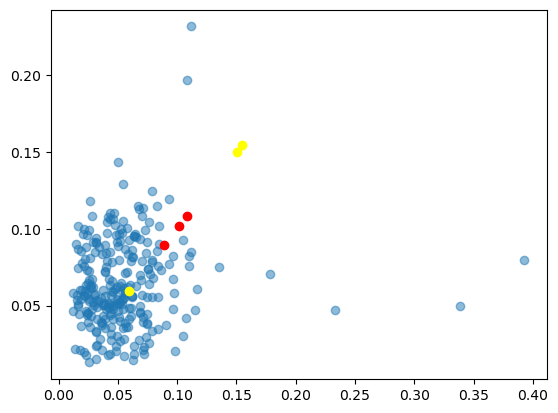

In [165]:
plt.scatter(smx_all_IR[np.arange(label_ir.shape[0]),label_ir],
            smx_all_Raman[np.arange(label_ir.shape[0]),label_ir], alpha=.5)

i = 2
for x,y in zip(smx_all_Raman_test[label_amb_ir==3,:][i],smx_all_Raman_test[label_amb_ir==3,:][i]):
    plt.scatter(x,y, c='r')

i = 0
for x,y in zip(smx_all_Raman_test[label_amb_ir<3,:][i],smx_all_Raman_test[label_amb_ir<3,:][i]):
    plt.scatter(x,y, c='yellow')

(array([15.73979937,  4.75163755,  0.29697735,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.29697735]),
 array([0.00915098, 0.05657718, 0.10400338, 0.15142958, 0.19885578,
        0.24628198, 0.29370818, 0.34113438, 0.38856058, 0.43598678,
        0.48341298]),
 <BarContainer object of 10 artists>)

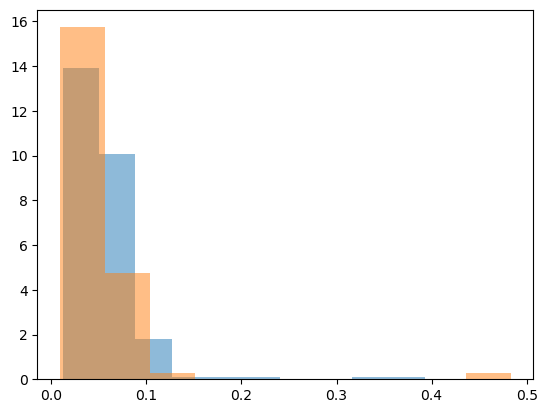

In [166]:
plt.hist(smx_all_IR[np.arange(label_ir.shape[0]),label_ir], alpha=.5, density=True)
plt.hist(smx_all_IR_test[label_amb_ir<3,:][np.arange(sum(label_amb_ir<3)),label_amb_ir[label_amb_ir<3]], 
         alpha=.5, density=True)


(array([ 12.5948677 ,   0.        ,   0.        ,   0.        ,
         12.5948677 ,   0.        ,  18.89230156,  81.86664007,
        125.94867704,  69.27177237]),
 array([0.06380708, 0.06692071, 0.07003433, 0.07314795, 0.07626158,
        0.0793752 , 0.08248883, 0.08560245, 0.08871608, 0.0918297 ,
        0.09494332]),
 <BarContainer object of 10 artists>)

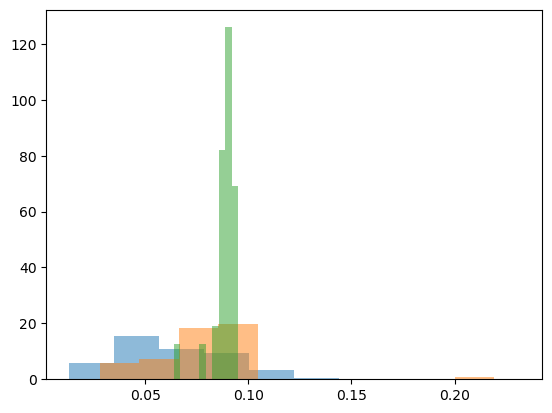

In [167]:
plt.hist(smx_all_Raman[np.arange(label_ir.shape[0]),label_ir], alpha=.5, density=True)
#plt.hist(smx_all_Raman_test[np.arange(label_amb_ir.shape[0]),label_amb_ir], alpha=.5, density=True)

plt.hist(smx_all_Raman_test[label_amb_ir<3,:][np.arange(sum(label_amb_ir<3)),label_amb_ir[label_amb_ir<3]], 
         alpha=.5, density=True)

plt.hist(np.min(smx_all_Raman_test[label_amb_ir==3,:],1), 
         alpha=.5, density=True)

In [192]:
TPR = defaultdict(list)
FPR = defaultdict(list)
U_quant_env_list = defaultdict(list)

for i in tqdm(range(100)):
    #alpha = .25
    seed = i
    K = 2
    quant_smx_list = []
    rest_smx_list = []
    cal_smx_list = []
    val_smx_list = []
    U_list = gen_u(K, seed=0)

    
    label_cal_ir = label_ir
    val_labels = None#label_amb_ir

    for i in range(K):
            #quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
        quant_smx, cal_smx, quant_labels, cal_labels, idx_quant = split_cal_test(score_list[i], label_cal_ir, cal_prop=0.6, seed=seed)

        val_smx, _ = score_list_test[i], None

            #y_val = list(label_table.iloc[val_labels,1])

            #y_val_ir = np.array(notes_mix_std.loc[~idx_quant,:].loc[~idx,'polymer_ir'])
            #y_val_raman = np.array(notes_mix_std.loc[~idx_quant,:].loc[~idx,'polymer_raman'])

        quant_smx_list.append(quant_smx)
        #rest_smx_list.append(rest_smx)
        cal_smx_list.append(cal_smx)
        val_smx_list.append(val_smx)

    n = cal_labels.shape[0]

    for alpha in (np.linspace(0.01,.99,99)):

        prediction_sets, U_quant_env = mvcp_2(quant_smx_list, 
                                                     quant_labels,   
                                                     cal_smx_list,   
                                                     cal_labels,   
                                                     val_smx_list,   
                                                     alpha,     
                                                     val_labels,                 
                                                     U=U_list[0])

        U_quant_env_list[alpha].append(U_quant_env)
        prediction_sets_n_mvcp = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
        prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n_mvcp])

        zero_label = np.where(prediction_sets_size == 0)[0]
        single_label = np.where(prediction_sets_size == 1)[0]
        mult_label = np.where(prediction_sets_size > 1)[0]

        #'mvcp'+'_'+str(int(alpha*100))
        TPR[alpha].append(np.mean(prediction_sets[label_amb_ir<3,:][np.arange(label_amb_ir[label_amb_ir<3].shape[0]), 
                                                                     label_amb_ir[label_amb_ir<3]]))
        #FPR.append(np.mean(label_amb_ir[prediction_sets_size>0] == 3))
        FPR[alpha].append(np.sum(label_amb_ir[prediction_sets_size>0] == 3) / sum(label_amb_ir == 3))

        prediction_sets, qhat = conform_pred(cal_smx_list[0], val_smx_list[0], cal_labels, n, alpha, cond=0)

        prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
        prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

        #TPR['IR'].append(np.mean(prediction_sets[label_amb_ir<3,:][np.arange(label_amb_ir[label_amb_ir<3].shape[0]), label_amb_ir[label_amb_ir<3]]))
        #FPR.append(np.mean(label_amb_ir[prediction_sets_size>0] == 3))
        #FPR['IR'].append(np.sum(label_amb_ir[prediction_sets_size>0] == 3) / sum(label_amb_ir == 3))

        prediction_sets, qhat = conform_pred(cal_smx_list[1], val_smx_list[1], cal_labels, n, alpha, cond=0)

        prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
        prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

        #TPR['Raman'].append(np.mean(prediction_sets[label_amb_ir<3,:][np.arange(label_amb_ir[label_amb_ir<3].shape[0]), label_amb_ir[label_amb_ir<3]]))
        #FPR.append(np.mean(label_amb_ir[prediction_sets_size>0] == 3))
        #FPR['Raman'].append(np.sum(label_amb_ir[prediction_sets_size>0] == 3) / sum(label_amb_ir == 3))



  0%|                                                                                                                   | 0/100 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_6556/2373691010.py:62: DeprecationWarning: the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(cal_smx_list[0], val_smx_list[0], cal_labels, n, alpha, cond=0)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_6556/2373691010.py:71: DeprecationWarning: the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(cal_smx_list[1], val_smx_list[1], cal_labels, 

In [231]:
score_list_test[0].shape

(122, 3)

In [232]:
IR_spectra_amb.shape

(127, 543)

In [277]:
top_hqi_values = 1-pd.DataFrame(np.concatenate(score_list_test, axis=1))
top_hqi_values.columns = [x + ' (IR)' for x in label_table['polymer']] + [x + ' (Raman)' for x in label_table['polymer']]
top_hqi_values = pd.concat([top_hqi_values, IR_spectra_amb.iloc[:,-6:-1]], axis=1)
top_hqi_values = top_hqi_values.sort_values(by='polymer')
top_hqi_values

,PE (IR),PP (IR),PSL (IR),PE (Raman),PP (Raman),PSL (Raman),polymer_raman,polymer_ir,comments,polymer,id
60,0.981291,0.491438,0.588913,0.906887,0.902745,0.886201,LDPE,LDPE,NaN,PE,144
26,0.986016,0.443193,0.491600,0.906381,0.903270,0.891686,LDPE,LDPE,NaN,PE,52
90,0.951508,0.811101,0.817767,0.924308,0.880691,0.804871,LDPE,LDPE,NaN,PE,206
83,0.962648,0.755442,0.768977,0.911476,0.897730,0.862833,LDPE,LDPE,NaN,PE,193
33,0.968344,0.667350,0.732808,0.914630,0.893988,0.849853,LDPE,LDPE,NaN,PE,77
...,...,...,...,...,...,...,...,...,...,...,...
87,0.897612,0.901262,0.908290,0.901683,0.906533,0.903113,UNS,AMB,FLUORESCENCE,z_AMB,200
30,0.891304,0.892936,0.915479,0.893393,0.881111,0.915113,LOW,AMB,NaN,z_AMB,67
55,0.899984,0.899132,0.909467,0.898673,0.894701,0.910646,LOW,AMB,NaN,z_AMB,138
38,0.893765,0.892129,0.914811,0.899186,0.896363,0.910188,AMB,AMB,NaN,z_AMB,82


In [217]:
calibration = pd.DataFrame({
    'IR':1-score_list[0][range(label_cal_ir.shape[0]), label_cal_ir],
    'Raman':1-score_list[1][range(label_cal_ir.shape[0]), label_cal_ir]})


array([0.02556147, 0.0324405 , 0.06299855, 0.04352469, 0.05885212,
       0.0716032 , 0.04844663, 0.05271633, 0.0350533 , 0.01357832,
       0.05098062, 0.049014  , 0.01829238, 0.06844948, 0.11498124,
       0.05951208, 0.05508328, 0.01586873, 0.02585166, 0.03398308,
       0.07096265, 0.07909206, 0.06374064, 0.06357888, 0.01823992,
       0.083549  , 0.03141992, 0.09829911, 0.064393  , 0.04201539,
       0.09062672, 0.05386312, 0.06811369, 0.05148497, 0.02170932,
       0.04798975, 0.07233952, 0.02612495, 0.02875913, 0.02222687,
       0.08633059, 0.03646046, 0.02294627, 0.05910562, 0.02157096,
       0.03185565, 0.11131242, 0.04159944, 0.03207125, 0.05532367,
       0.06136743, 0.02085996, 0.07472085, 0.03690374, 0.0436825 ,
       0.03277198, 0.10506121, 0.04763965, 0.0325152 , 0.03734695,
       0.10989276, 0.0232881 , 0.06198078, 0.07581019, 0.03150554,
       0.02964784, 0.04890883, 0.04000595, 0.10510317, 0.07850332,
       0.05666363, 0.02924049, 0.05365484, 0.06139292, 0.05077

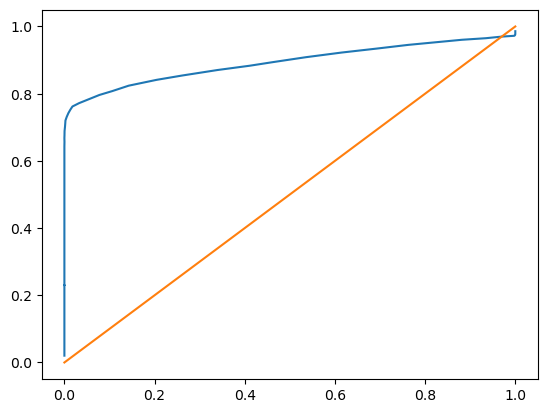

In [278]:
plt.plot(pd.DataFrame(FPR).mean(),
         pd.DataFrame(TPR).mean())

plt.plot(np.linspace(0,1),
         np.linspace(0,1))

#plt.fill_between(pd.DataFrame(FPR).mean(),
#                 pd.DataFrame(TPR).mean() - pd.DataFrame(TPR).std(),
#                 pd.DataFrame(TPR).mean() + pd.DataFrame(TPR).std(), alpha=.2)

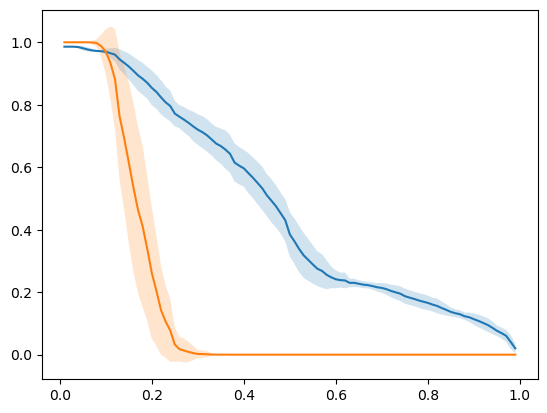

In [199]:
plt.plot(pd.DataFrame(TPR).mean())

plt.fill_between(pd.DataFrame(FPR).mean().index,
                 pd.DataFrame(TPR).mean() - pd.DataFrame(TPR).std(),
                 pd.DataFrame(TPR).mean() + pd.DataFrame(TPR).std(), alpha=.2)

plt.plot(pd.DataFrame(FPR).mean())

plt.fill_between(pd.DataFrame(FPR).mean().index,
                 pd.DataFrame(FPR).mean() - pd.DataFrame(FPR).std(),
                 pd.DataFrame(FPR).mean() + pd.DataFrame(FPR).std(), alpha=.2)

In [210]:
pd.DataFrame({'TPR (mean)':pd.DataFrame(TPR).mean(),
              'FPR (mean)':pd.DataFrame(FPR).mean(),
              'TPR (standard deviation)':pd.DataFrame(TPR).std(),
              'FPR (standard deviation)':pd.DataFrame(FPR).std(),
              })

,TPR (mean),FPR (mean),TPR (standard deviation),FPR (standard deviation)
0.01,0.985915,1.0,1.338979e-15,0.0
0.02,0.985915,1.0,1.338979e-15,0.0
0.03,0.985915,1.0,1.338979e-15,0.0
0.04,0.984789,1.0,3.840281e-03,0.0
0.05,0.980986,1.0,6.751725e-03,0.0
...,...,...,...,...
0.95,0.076620,0.0,1.690615e-02,0.0
0.96,0.069014,0.0,1.762341e-02,0.0
0.97,0.060423,0.0,1.954223e-02,0.0
0.98,0.040704,0.0,2.182835e-02,0.0


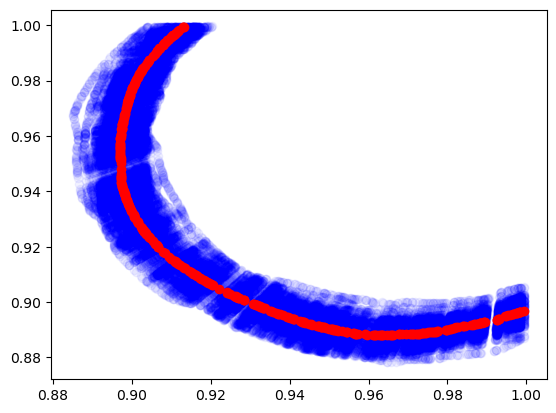

In [185]:
for x in U_quant_env_list[0.2]:
    plt.scatter(1-x[:,0],
                1-x[:,1], color='blue', alpha=.05)
plt.scatter(1-np.array(U_quant_env_list[0.2]).mean(0)[:,0],
            1-np.array(U_quant_env_list[0.2]).mean(0)[:,1], color='red')

In [208]:
U_quant_env_list.keys()

dict_keys([0.01, 0.02, 0.03, 0.04, 0.05, 0.060000000000000005, 0.06999999999999999, 0.08, 0.09, 0.09999999999999999, 0.11, 0.12, 0.13, 0.14, 0.15000000000000002, 0.16, 0.17, 0.18000000000000002, 0.19, 0.2, 0.21000000000000002, 0.22, 0.23, 0.24000000000000002, 0.25, 0.26, 0.27, 0.28, 0.29000000000000004, 0.3, 0.31, 0.32, 0.33, 0.34, 0.35000000000000003, 0.36000000000000004, 0.37, 0.38, 0.39, 0.4, 0.41000000000000003, 0.42000000000000004, 0.43, 0.44, 0.45, 0.46, 0.47000000000000003, 0.48000000000000004, 0.49, 0.5, 0.51, 0.52, 0.53, 0.54, 0.55, 0.56, 0.5700000000000001, 0.5800000000000001, 0.59, 0.6, 0.61, 0.62, 0.63, 0.64, 0.65, 0.66, 0.67, 0.68, 0.6900000000000001, 0.7000000000000001, 0.7100000000000001, 0.72, 0.73, 0.74, 0.75, 0.76, 0.77, 0.78, 0.79, 0.8, 0.81, 0.8200000000000001, 0.8300000000000001, 0.8400000000000001, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9, 0.91, 0.92, 0.93, 0.9400000000000001, 0.9500000000000001, 0.9600000000000001, 0.97, 0.98, 0.99])

In [214]:

for i, alpha in enumerate(U_quant_env_list.keys()):
    if i == 0:
        df_envelopes = pd.DataFrame({
            'x - '+str(1-alpha) + ' (mean)':1-np.array(U_quant_env_list[alpha]).mean(0)[:,0],
            'y - '+str(1-alpha) + ' (mean)':1-np.array(U_quant_env_list[alpha]).mean(0)[:,1]
                      })
    else:
        df_envelopes = pd.concat([df_envelopes,
                        pd.DataFrame({
                            'x - '+str(1-alpha) + ' (mean)':1-np.array(U_quant_env_list[alpha]).mean(0)[:,0],
                            'y - '+str(1-alpha) + ' (mean)':1-np.array(U_quant_env_list[alpha]).mean(0)[:,1]
                      })], axis=1)
df_envelopes

,x - 0.99 (mean),y - 0.99,x - 0.98 (mean),y - 0.98,x - 0.97 (mean),y - 0.97,x - 0.96 (mean),y - 0.96,x - 0.95 (mean),y - 0.95,...,x - 0.04999999999999993 (mean),y - 0.04999999999999993,x - 0.039999999999999925 (mean),y - 0.039999999999999925,x - 0.030000000000000027 (mean),y - 0.030000000000000027,x - 0.020000000000000018 (mean),y - 0.020000000000000018,x - 0.010000000000000009 (mean),y - 0.010000000000000009
0,0.592396,0.907539,0.589298,0.906837,0.705699,0.933241,0.783924,0.950985,0.836619,0.962939,...,0.953216,0.989388,0.954129,0.989595,0.954714,0.989727,0.956167,0.990057,0.954856,0.989760
1,0.882312,0.730544,0.852504,0.662296,0.882344,0.730617,0.911648,0.797711,0.929618,0.838856,...,0.974175,0.940871,0.974655,0.941970,0.975054,0.942885,0.975827,0.944654,0.976069,0.945208
2,0.640140,0.811688,0.619223,0.800743,0.706348,0.846335,0.783233,0.886568,0.835018,0.913666,...,0.945716,0.971593,0.946701,0.972109,0.947663,0.972613,0.949362,0.973501,0.948719,0.973165
3,0.588272,0.934408,0.589634,0.934625,0.712704,0.954231,0.788879,0.966367,0.840666,0.974617,...,0.956676,0.993098,0.957569,0.993240,0.958356,0.993366,0.959634,0.993569,0.959125,0.993488
4,0.933146,0.734061,0.920478,0.683668,0.936734,0.748333,0.952530,0.811166,0.959724,0.839783,...,0.985491,0.942283,0.985810,0.943552,0.986206,0.945127,0.986851,0.947696,0.987325,0.949579
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,0.588045,0.972776,0.596017,0.973303,0.723543,0.981730,0.796516,0.986553,0.849385,0.990047,...,0.963275,0.997573,0.964019,0.997622,0.964783,0.997673,0.965685,0.997732,0.965946,0.997750
396,0.815680,0.730428,0.770635,0.664548,0.818145,0.734033,0.863755,0.800738,0.895041,0.846495,...,0.961740,0.944044,0.962444,0.945073,0.962963,0.945832,0.963925,0.947240,0.963360,0.946413
397,0.751599,0.740041,0.708890,0.695344,0.766155,0.755274,0.825807,0.817701,0.868485,0.862366,...,0.952742,0.950543,0.953655,0.951498,0.954388,0.952265,0.955594,0.953527,0.954934,0.952837
398,0.982304,0.744454,0.979588,0.705233,0.983908,0.767621,0.987976,0.826361,0.989671,0.850834,...,0.996503,0.949501,0.996597,0.950859,0.996723,0.952679,0.996955,0.956032,0.997275,0.960643


In [216]:
for i, alpha in enumerate(U_quant_env_list.keys()):
    if i == 0:
        df_envelopes = pd.DataFrame({
            'x - '+str(1-alpha) + ' (standard deviation)':1-np.array(U_quant_env_list[alpha]).std(0)[:,0],
            'y - '+str(1-alpha) + ' (standard deviation)':1-np.array(U_quant_env_list[alpha]).std(0)[:,1]
                      })
    else:
        df_envelopes = pd.concat([df_envelopes,
                        pd.DataFrame({
                            'x - '+str(1-alpha) + ' (standard deviation)':1-np.array(U_quant_env_list[alpha]).std(0)[:,0],
                            'y - '+str(1-alpha) + ' (standard deviation)':1-np.array(U_quant_env_list[alpha]).std(0)[:,1]
                      })], axis=1)
df_envelopes

,x - 0.99 (standard deviation),y - 0.99 (standard deviation),x - 0.98 (standard deviation),y - 0.98 (standard deviation),x - 0.97 (standard deviation),y - 0.97 (standard deviation),x - 0.96 (standard deviation),y - 0.96 (standard deviation),x - 0.95 (standard deviation),y - 0.95 (standard deviation),...,x - 0.04999999999999993 (standard deviation),y - 0.04999999999999993 (standard deviation),x - 0.039999999999999925 (standard deviation),y - 0.039999999999999925 (standard deviation),x - 0.030000000000000027 (standard deviation),y - 0.030000000000000027 (standard deviation),x - 0.020000000000000018 (standard deviation),y - 0.020000000000000018 (standard deviation),x - 0.010000000000000009 (standard deviation),y - 0.010000000000000009 (standard deviation)
0,0.876438,0.971971,0.899929,0.977300,0.921016,0.982083,0.956636,0.990163,0.972059,0.993662,...,0.997147,0.999353,0.996763,0.999266,0.995993,0.999091,0.994560,0.998766,0.992683,0.998340
1,0.951813,0.889673,0.947058,0.878785,0.966976,0.924389,0.981228,0.957020,0.986037,0.968030,...,0.998493,0.996549,0.998337,0.996193,0.998012,0.995449,0.997307,0.993834,0.996510,0.992009
2,0.888359,0.941579,0.894654,0.944873,0.923254,0.959839,0.958961,0.978525,0.972170,0.985437,...,0.996926,0.998392,0.996460,0.998148,0.995755,0.997778,0.994198,0.996964,0.992046,0.995838
3,0.875092,0.980101,0.901011,0.984230,0.922051,0.987582,0.955337,0.992885,0.972234,0.995577,...,0.997166,0.999549,0.996834,0.999496,0.996270,0.999406,0.995002,0.999204,0.993696,0.998996
4,0.972415,0.890269,0.967709,0.871548,0.979718,0.919320,0.988357,0.953684,0.991912,0.967826,...,0.999172,0.996705,0.999123,0.996511,0.999001,0.996027,0.998765,0.995087,0.998166,0.992705
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,0.874588,0.991712,0.902144,0.993533,0.924501,0.995011,0.954730,0.997008,0.971182,0.998096,...,0.997665,0.999846,0.997399,0.999828,0.996813,0.999789,0.995635,0.999712,0.994716,0.999651
396,0.929653,0.897116,0.924033,0.888897,0.953980,0.932694,0.974643,0.962914,0.980696,0.971768,...,0.997766,0.996733,0.997495,0.996337,0.996859,0.995406,0.995671,0.993669,0.994421,0.991840
397,0.914070,0.910072,0.906603,0.902257,0.942097,0.939402,0.970509,0.969137,0.977444,0.976394,...,0.997175,0.997044,0.996842,0.996695,0.996154,0.995975,0.994591,0.994339,0.993270,0.992957
398,0.992619,0.893412,0.991032,0.870487,0.994320,0.917981,0.996845,0.954435,0.997760,0.967649,...,0.999813,0.997302,0.999798,0.997080,0.999766,0.996619,0.999748,0.996354,0.999644,0.994854


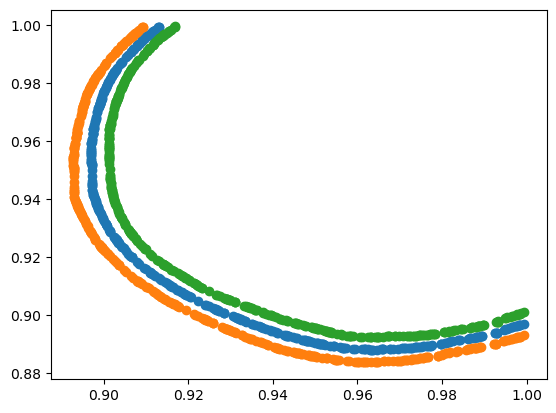

In [186]:
alpha = .2
plt.scatter(1-np.array(U_quant_env_list[alpha]).mean(0)[:,0],
            1-np.array(U_quant_env_list[alpha]).mean(0)[:,1])

plt.scatter(1-(np.array(U_quant_env_list[alpha]).mean(0)[:,0] + np.array(U_quant_env_list[alpha]).std(0)[:,0]),
            1-(np.array(U_quant_env_list[alpha]).mean(0)[:,1] + np.array(U_quant_env_list[alpha]).std(0)[:,1]))

plt.scatter(1-(np.array(U_quant_env_list[alpha]).mean(0)[:,0] - np.array(U_quant_env_list[alpha]).std(0)[:,0]),
            1-(np.array(U_quant_env_list[alpha]).mean(0)[:,1] - np.array(U_quant_env_list[alpha]).std(0)[:,1]))


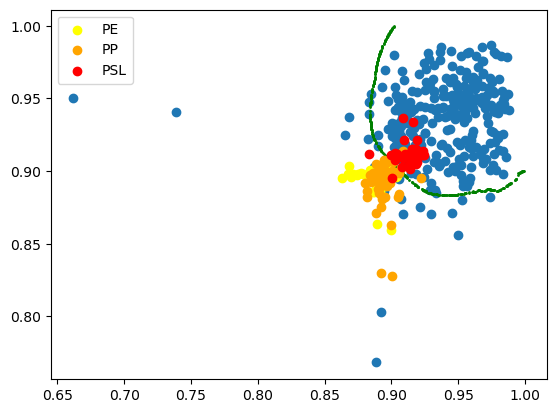

In [74]:

idx_amb = label_amb_ir == 3

plt.scatter(1-cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels],
            1-cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels])

#plt.scatter(U_quant_env_list[np.linspace(0.01,.99,100)[10]][:,0],
#            U_quant_env_list[np.linspace(0.01,.99,100)[10]][:,1], color='green', s=1)

#plt.scatter(U_quant_env_list[np.linspace(0.01,.99,100)[15]][:,0],
#            U_quant_env_list[np.linspace(0.01,.99,100)[15]][:,1], color='green', s=1)

#plt.scatter(U_quant_env_list[np.linspace(0.01,.99,100)[5]][:,0],
#            U_quant_env_list[np.linspace(0.01,.99,100)[5]][:,1], color='green', s=1)

plt.scatter(1-U_quant_env_list[np.linspace(0.01,.99,100)[20]][:,0],
            1-U_quant_env_list[np.linspace(0.01,.99,100)[20]][:,1], color='green', s=1)

plt.scatter(1-val_smx_list[0][idx_amb][np.arange(np.sum(idx_amb)),0],
            1-val_smx_list[1][idx_amb][np.arange(np.sum(idx_amb)),0], color='yellow', label="PE")

plt.scatter(1-val_smx_list[0][idx_amb][np.arange(np.sum(idx_amb)),1],
            1-val_smx_list[1][idx_amb][np.arange(np.sum(idx_amb)),1], color='orange', label="PP")

plt.scatter(1-val_smx_list[0][idx_amb][np.arange(np.sum(idx_amb)),2],
            1-val_smx_list[1][idx_amb][np.arange(np.sum(idx_amb)),2], color='red', label="PSL")

plt.legend()

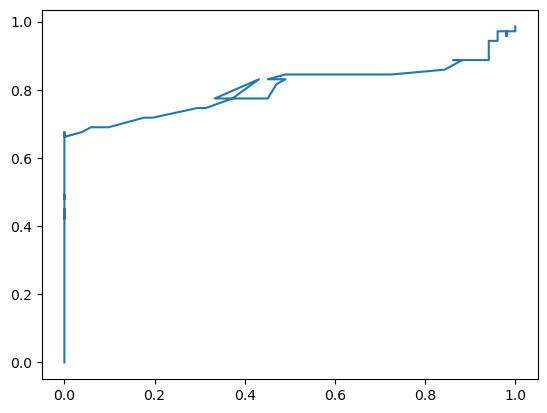

In [75]:
plt.plot(FPR['mvcp'], TPR['mvcp'])

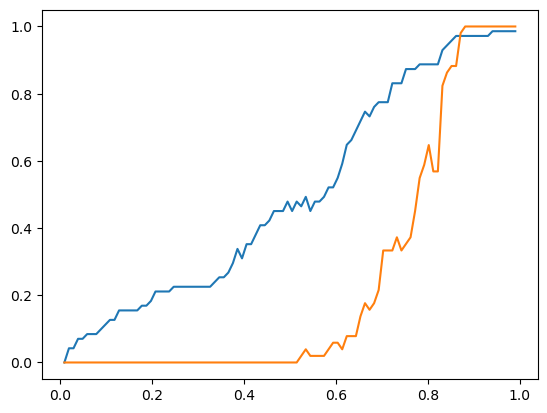

In [65]:
plt.plot(1-np.linspace(0.01,.99,100),
         TPR['mvcp'])

plt.plot(1-np.linspace(0.01,.99,100),
         FPR['mvcp'])

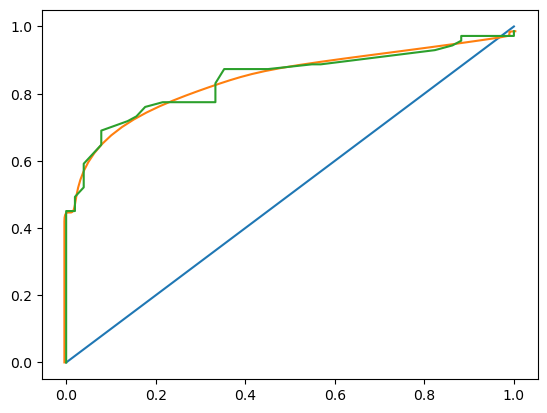

In [43]:
plt.plot(np.linspace(0,1), np.linspace(0,1))
plt.plot(y_fit_FPR, 
         y_fit_TPR)
plt.plot(FPR_mvcp,
         TPR_mvcp)


In [44]:
FPR_mvcp = []
x_max = np.max(FPR['mvcp'])
idx = []
for i, x in enumerate(FPR['mvcp']):
    if x<=x_max:
        FPR_mvcp.append(x)
        idx.append(i)
        x_max = x
    else:
        FPR_mvcp.append(x_max)

TPR_mvcp = []
x_max = np.max(TPR['mvcp'])
idx = []
for i, x in enumerate(TPR['mvcp']):
    if x<=x_max:
        TPR_mvcp.append(x)
        idx.append(i)
        x_max = x
    else:
        TPR_mvcp.append(x_max)
        

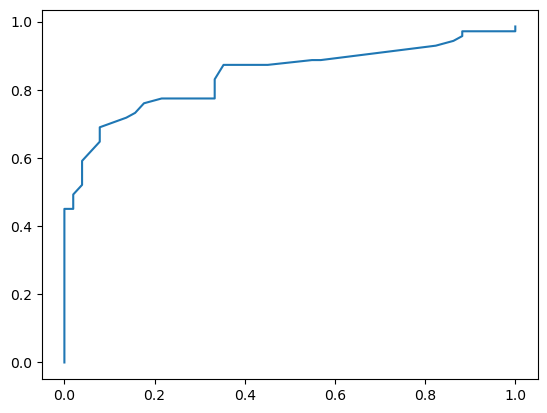

In [45]:
plt.plot(FPR_mvcp,
         TPR_mvcp)


/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_6556/2299437076.py:4: RankWarning: Polyfit may be poorly conditioned
  coefficients = np.polyfit(x,
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_6556/2299437076.py:9: RankWarning: Polyfit may be poorly conditioned
  coefficients = np.polyfit(x,


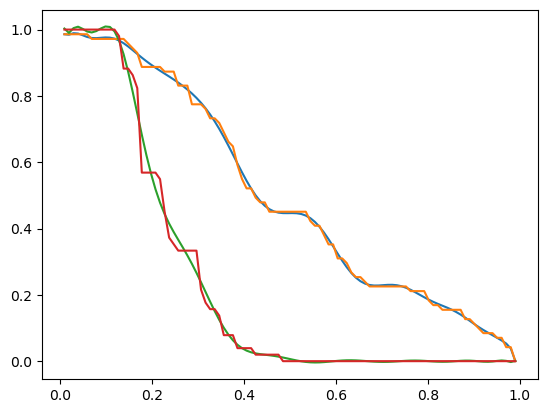

In [46]:
import numpy as np

x = np.linspace(0.01,.99,100)
coefficients = np.polyfit(x,
                          TPR_mvcp, deg=20)  # Quadratic fit
poly_func = np.poly1d(coefficients)
y_fit = poly_func(x)

coefficients = np.polyfit(x,
                          FPR_mvcp, deg=20)  # Quadratic fit
poly_func = np.poly1d(coefficients)
y_fit2 = poly_func(x)



plt.plot(np.linspace(0.01,.99,100),
         y_fit)

plt.plot(np.linspace(0.01,.99,100),
         TPR_mvcp)


plt.plot(np.linspace(0.01,.99,100),
         y_fit2)

plt.plot(np.linspace(0.01,.99,100),
         FPR_mvcp)


In [47]:
y_fit_FPR = []
x_max = np.max(y_fit2)
for i, x in enumerate(y_fit2):
    if x<=x_max:
        y_fit_FPR.append(x)
        x_max = x
    else:
        y_fit_FPR.append(x_max)

y_fit_TPR = []
x_max = np.max(y_fit)
for i, x in enumerate(y_fit):
    if x<=x_max:
        y_fit_TPR.append(x)
        x_max = x
    else:
        y_fit_TPR.append(x_max)
        

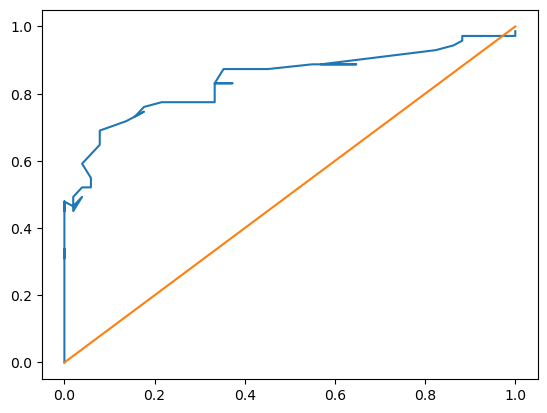

In [48]:
plt.plot(FPR['mvcp'], TPR['mvcp'])
plt.plot(np.linspace(0,1),np.linspace(0,1))

In [49]:
alpha = .99
prediction_sets, qhat = conform_pred(cal_smx_list[0], val_smx_list[0], cal_labels, n, alpha, cond=0)

prediction_sets_n = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 60
Sets with one label: 2
Sets with >1 labels: 60
Mean set size: 1.0
Std set size: 0.9917694073609294


/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_6556/47276123.py:2: DeprecationWarning: the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  prediction_sets, qhat = conform_pred(cal_smx_list[0], val_smx_list[0], cal_labels, n, alpha, cond=0)


In [50]:
FPR_mvcp = []
x_max = np.max(FPR['mvcp'])
idx = []
for i, x in enumerate(FPR['mvcp']):
    if x<=x_max:
        FPR_mvcp.append(x)
        idx.append(i)
        x_max = x
        
FPR_mvcp

[1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 0.9803921568627451,
 0.8823529411764706,
 0.8823529411764706,
 0.8627450980392157,
 0.8235294117647058,
 0.5686274509803921,
 0.5686274509803921,
 0.5490196078431373,
 0.45098039215686275,
 0.37254901960784315,
 0.35294117647058826,
 0.3333333333333333,
 0.3333333333333333,
 0.3333333333333333,
 0.3333333333333333,
 0.21568627450980393,
 0.17647058823529413,
 0.1568627450980392,
 0.13725490196078433,
 0.0784313725490196,
 0.0784313725490196,
 0.0784313725490196,
 0.0392156862745098,
 0.0392156862745098,
 0.0196078431372549,
 0.0196078431372549,
 0.0196078431372549,
 0.0196078431372549,
 0.0196078431372549,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0]

In [51]:
idx = np.logical_and([True]+list(np.diff(FPR['mvcp'])<=0),
[True]+list(np.diff(TPR['mvcp'])<=0))
idx

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True,  True, False,  True,  True,
        True,  True,  True, False,  True,  True,  True,  True,  True,
        True, False,  True, False,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True, False,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True])

In [52]:
np.array(FPR['mvcp'])[idx]

array([1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 0.98039216, 0.88235294, 0.88235294,
       0.8627451 , 0.82352941, 0.56862745, 0.56862745, 0.58823529,
       0.54901961, 0.45098039, 0.37254902, 0.35294118, 0.33333333,
       0.33333333, 0.33333333, 0.33333333, 0.21568627, 0.17647059,
       0.15686275, 0.1372549 , 0.07843137, 0.07843137, 0.07843137,
       0.03921569, 0.05882353, 0.03921569, 0.01960784, 0.01960784,
       0.01960784, 0.01960784, 0.01960784, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

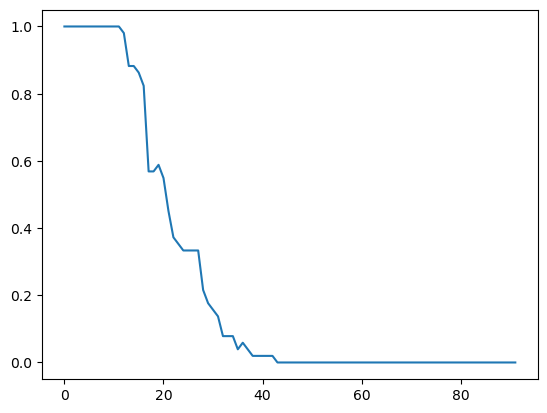

In [53]:
plt.plot(np.array(FPR['mvcp'])[idx])

ValueError: x and y must have same first dimension, but have shapes (93,) and (92,)

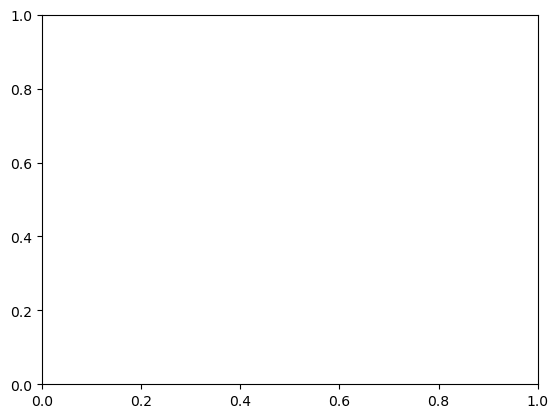

In [54]:
#plt.plot(np.array(FPR['mvcp'])[idx], np.array(TPR['mvcp'])[idx])
plt.plot(FPR_mvcp, np.array(TPR['mvcp'])[idx], label='mvcp')
plt.plot(np.array(FPR['IR'])[idx], np.array(TPR['IR'])[idx], label='IR cp')
plt.plot(np.array(FPR['Raman'])[idx], np.array(TPR['Raman'])[idx], label='Raman cp')
plt.plot(np.linspace(0,1),np.linspace(0,1))
plt.legend()

In [55]:
plt.plot(np.sort(FPR),np.array(TPR)[np.argsort(FPR)])
plt.plot(np.linspace(0,1),np.linspace(0,1))

AxisError: axis -1 is out of bounds for array of dimension 0

TypeError: unhashable type: 'collections.defaultdict'

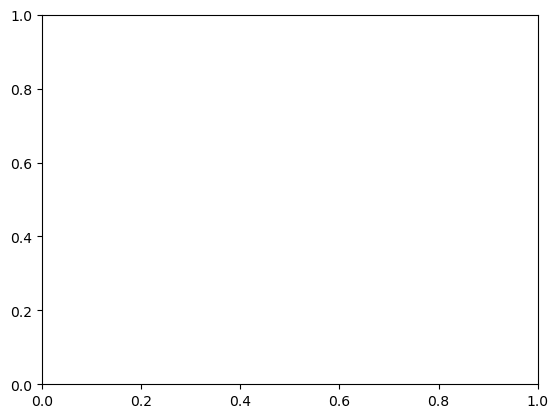

In [56]:
plt.plot(FPR,TPR)
plt.plot(np.linspace(0,1),np.linspace(0,1))

In [57]:
[(label_amb_table.iloc[x,1],y) for x,y in zip(label_amb_ir,prediction_sets_n_mvcp) if x == 6]

[]